In [41]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd

In [59]:
#funties om te gebruiken
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as

def lineaire_functie(x,a,b):
    return a*x + b
def plot(x_as, y_as, x_label, y_label, title):
    plt.plot(x_as, y_as, )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.show()

def lorentz(x, x0, gamma, A):
    return A * (0.5*gamma)**2 / ((x - x0)**2 + (0.5*gamma)**2)

def multi_lorentz(x, *params):
    # Laatste parameter is de achtergrond
    B = params[-1]
    y_model = np.zeros_like(x) + B

    # Door de overige parameters in stapjes van 3 lopen
    # (x0, gamma, A) per piek
    for i in range(0, len(params) - 1, 3):
        x0 = params[i]
        gamma = params[i + 1]
        A = params[i + 2]
        y_model += lorentz(x, x0, gamma, A)

    return y_model

def subtract(x_foreground, y_foreground, x_background, y_background):
    y_interpolated = np.interp(x_foreground, x_background, y_background)
    y_subtracted = y_foreground - y_interpolated

    return x_foreground, y_subtracted



def load_file(number: int, folder_path) -> pd.DataFrame:

    filename = f"TEK{number:04d}.CSV"
    filepath = os.path.join(folder_path, filename)

    if not os.path.exists(filepath):
        print(f"Bestand niet gevonden: {filename}")
        return None

    df = pd.read_csv(
        filepath,
        header=None,
        usecols=[3, 4],
        names=["time", "voltage"],
        encoding="utf-8"
    )

    # Verwijder rijen waar time of voltage geen getal is (de metadata-rijen)
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

    #print(f"Geladen: {filename} — {len(df)} datapunten")
    x_as = df["time"].values
    y_as = df["voltage"].values
    return x_as, y_as

def file_data(folder_path,N):
    x_subs = []
    y_subs = []
    teller_foreground = 0
    teller_background = 1

    while teller_foreground < N:
        x_foreground, y_foreground = load_file(teller_foreground, folder_path)
        x_background, y_background = load_file(teller_background, folder_path)

        if x_foreground is None or x_background is None:
            print(f"Fout bij het laden van bestanden: TEK{teller_foreground:04d} of TEK{teller_background:04d}")
            continue
        #subtration:
        x_subtracted, y_subtracted = subtract(x_foreground, y_foreground, x_background, y_background)
        x_subs.append(x_subtracted)
        y_subs.append(y_subtracted) 
        plt.plot(x_subtracted, y_subtracted)
        plt.xlabel("Time (s)")
        plt.ylabel("Voltage (V)")
        plt.title(f"Voltage vs Time - TEK{teller_foreground:04d} - TEK{teller_background:04d}, subtracted")
        plt.show()
        teller_foreground += 2
        teller_background += 2
    return x_subs, y_subs


19


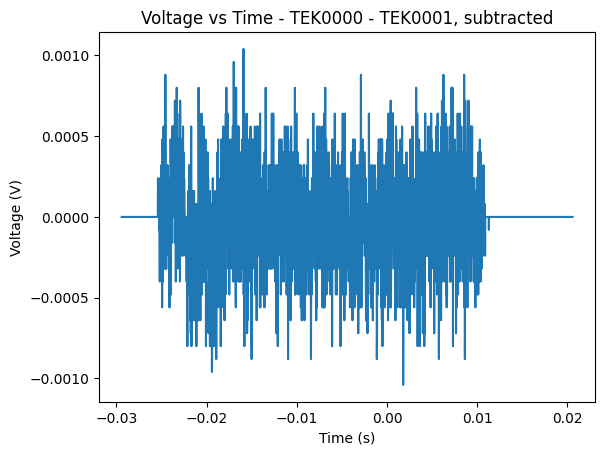

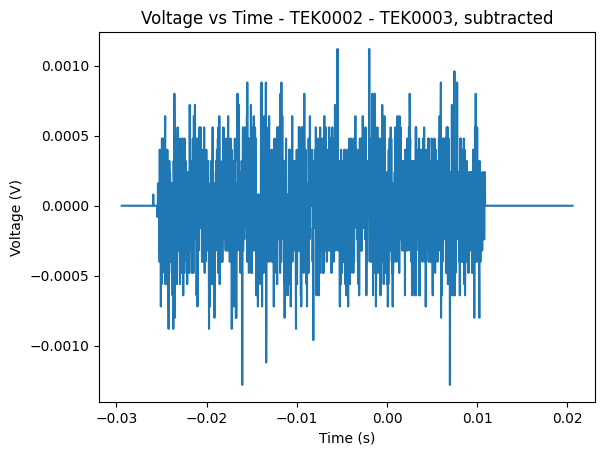

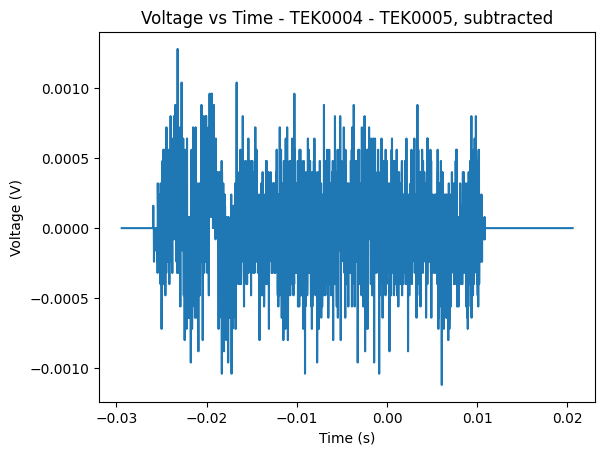

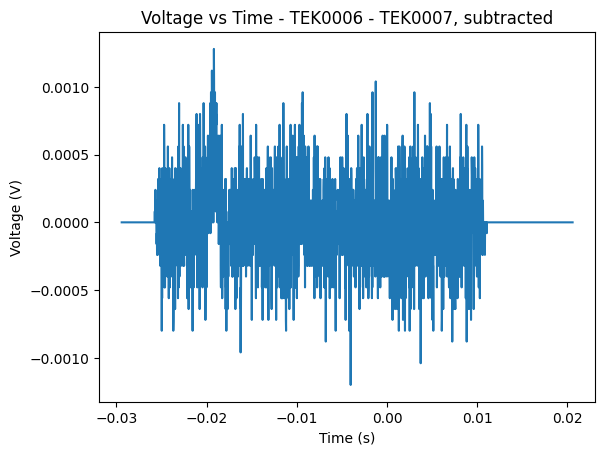

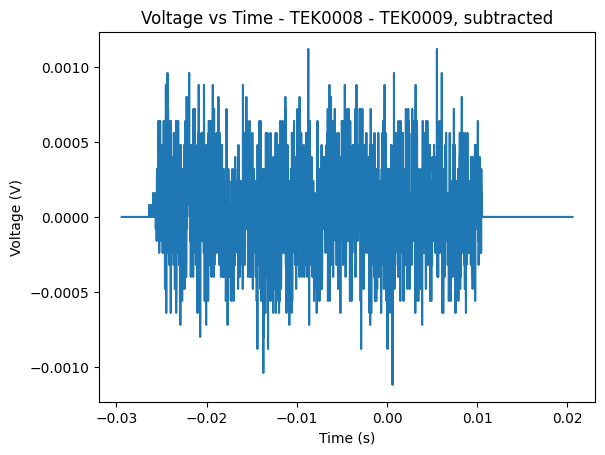

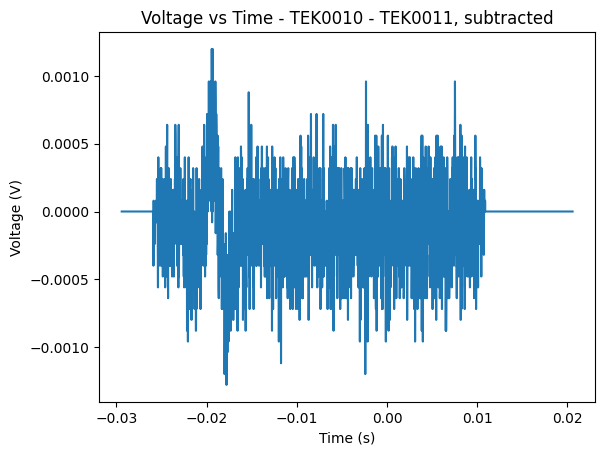

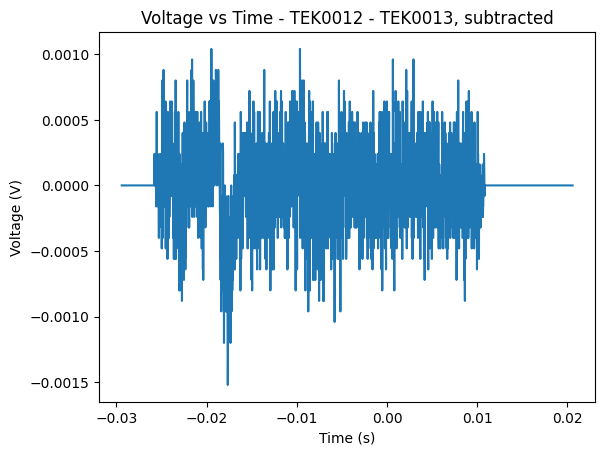

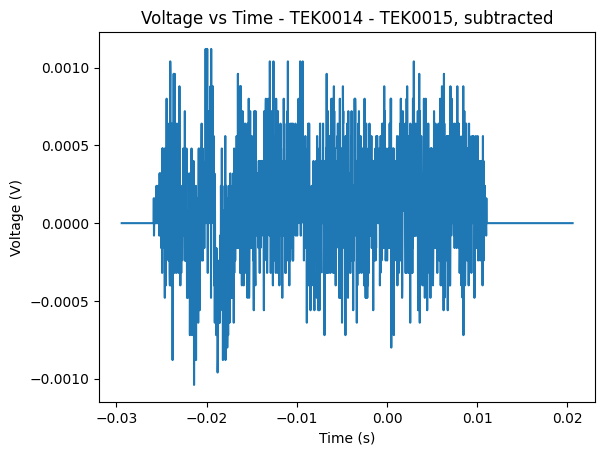

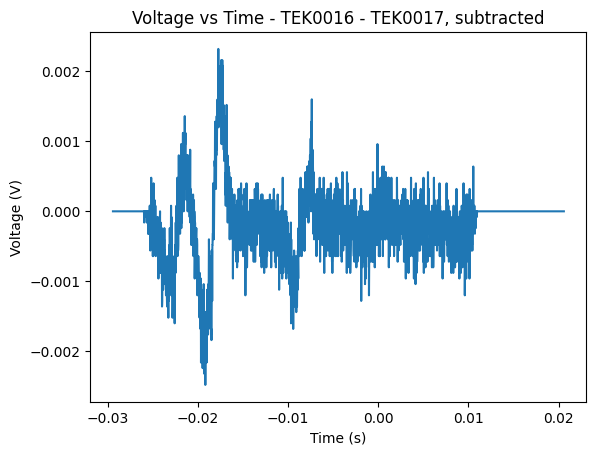

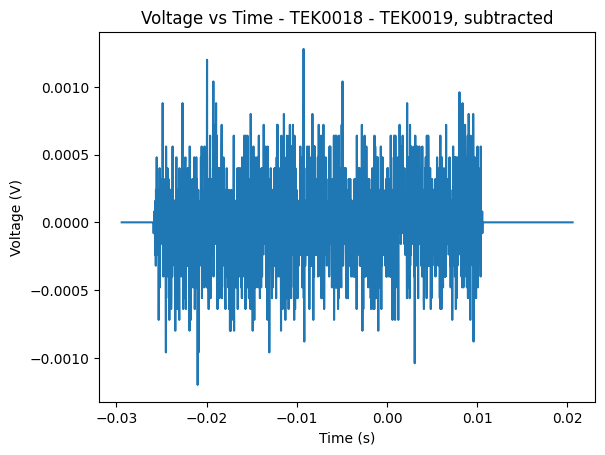

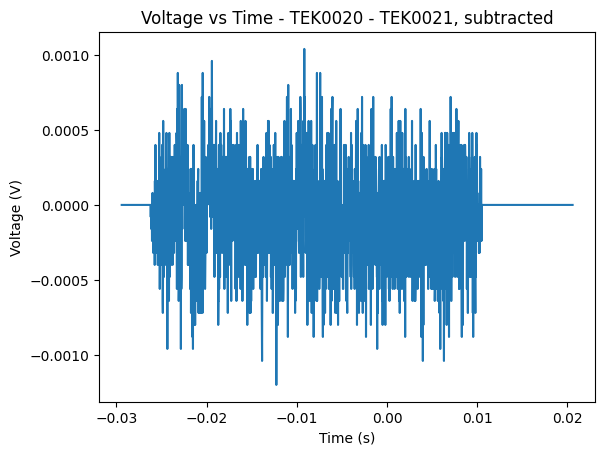

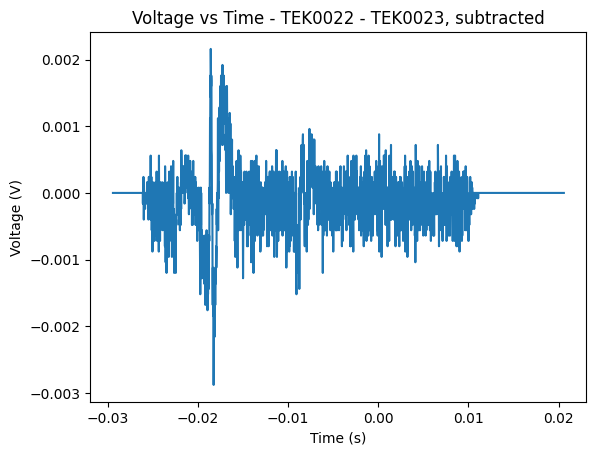

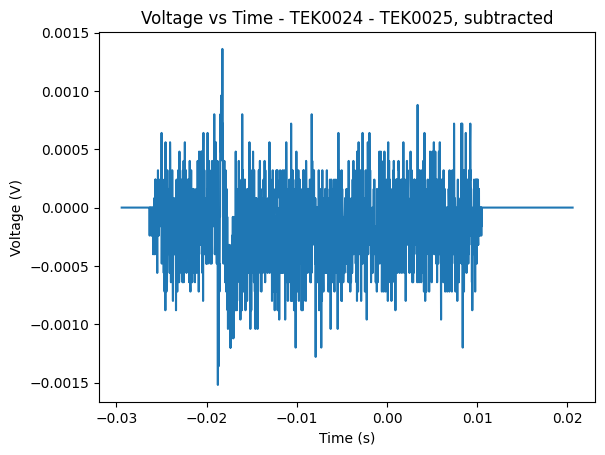

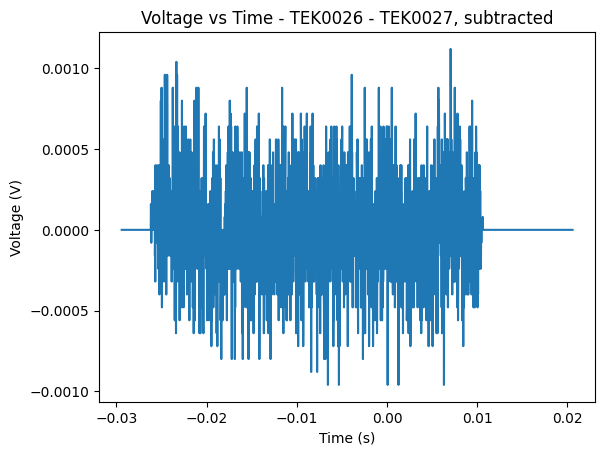

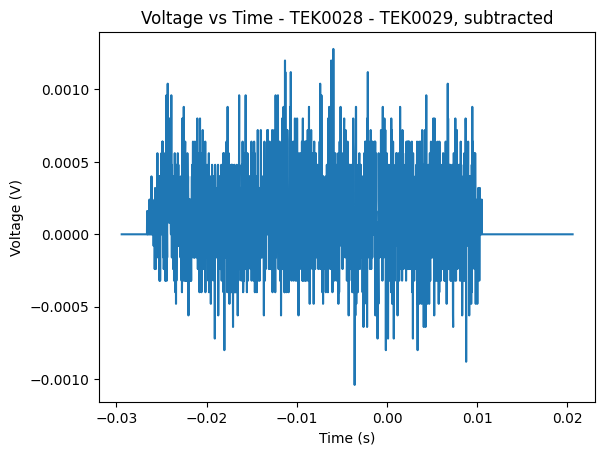

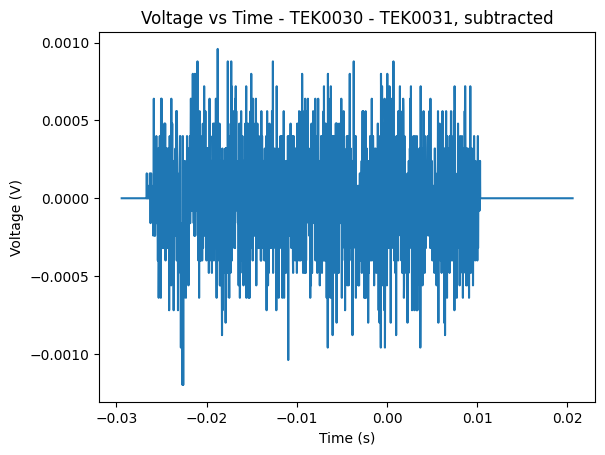

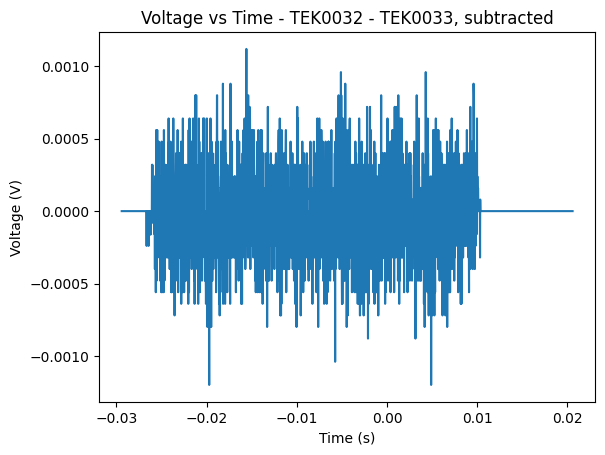

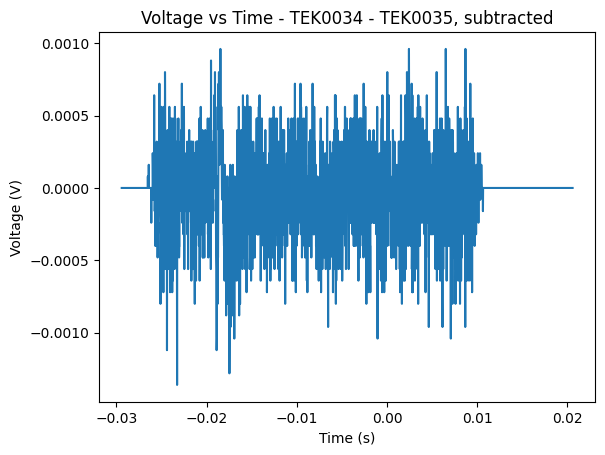

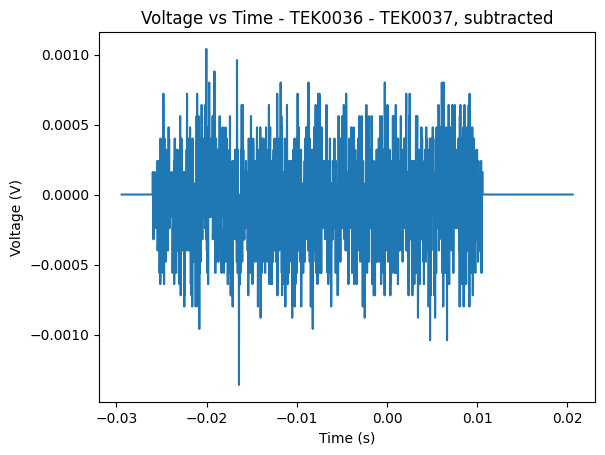

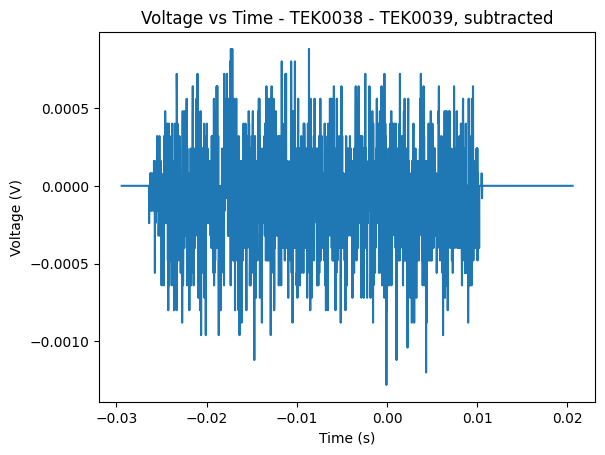

([array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-0.0294 , -0.02938, -0.02936, ...,  0.02054,  0.02056,  0.02058],
        shape=(2500,)),
  array([-

In [60]:
#Importeren van de Data: 
folder_pad = r"/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Data volledig spectrum"

x_subs = []
y_subs = []

teller_foreground = 0
teller_background = 1
while teller_foreground < 38:
    #forground: 
    x_foreground, y_foreground = load_file(teller_foreground, folder_pad)
    # plt.plot(x_foreground, y_foreground)
    # plt.xlabel("Time (s)")
    # plt.ylabel("Voltage (V)")
    # plt.title(f"Voltage vs Time - TEK{teller_foreground:04d}, foreground")
    # plt.show()
    #background:
    x_background, y_background = load_file(teller_background, folder_pad)
    # plt.plot(x_background, y_background)
    # plt.xlabel("Time (s)")
    # plt.ylabel("Voltage (V)")
    # plt.title(f"Voltage vs Time - TEK{teller_background:04d}, background")
    # plt.show()

    #subtration:
    x_subtracted, y_subtracted = subtract(x_foreground, y_foreground, x_background, y_background)
    x_subs.append(x_subtracted)
    y_subs.append(y_subtracted)
    # plt.plot(x_subtracted, y_subtracted)
    # plt.xlabel("Time (s)")
    # plt.ylabel("Voltage (V)")
    # plt.title(f"Voltage vs Time - TEK{teller_foreground:04d} - TEK{teller_background:04d}, subtracted")
    # plt.show()

    teller_foreground += 2
    teller_background += 2

print(len(x_subs))

file_data(folder_pad, 39)


─────────────────────────────────────────────
Piek 1:
  x0    = -0.01749 ± 0.00006
  gamma = -0.00045 ± 0.00015
  A     = 0.00049 ± 0.00008
Piek 2:
  x0    = -0.01449 ± 0.03638
  gamma = 0.00412 ± 0.06264
  A     = -0.00814 ± 8.29921
Piek 3:
  x0    = -0.01442 ± 0.03520
  gamma = 0.00400 ± 0.06280
  A     = 0.00802 ± 8.29920
Piek 4:
  x0    = 0.00434 ± 0.00092
  gamma = 0.00595 ± 0.00219
  A     = -0.00014 ± 0.00002
Achtergrond B = 0.00004 ± 0.00003
─────────────────────────────────────────────


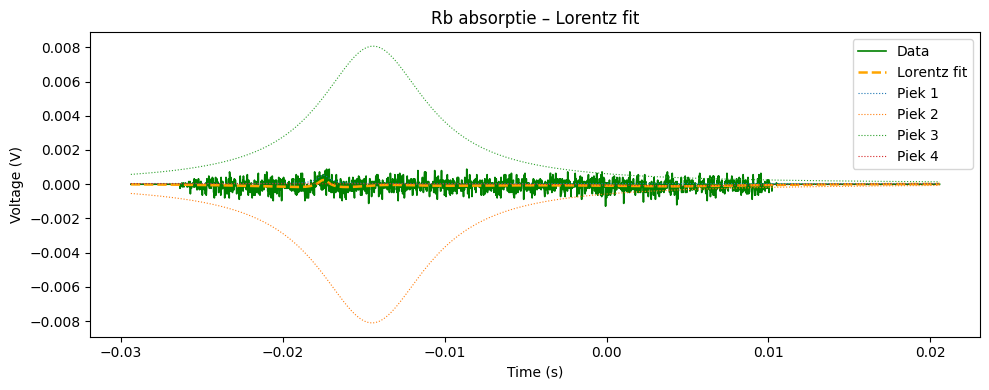

In [ ]:


# ── Lorentz bouwstenen ────────────────────────────────────────────────────────

def lorentz(x, x0, gamma, A):
    """Enkele Lorentz-piek (absorptie → negatieve A)."""
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    """
    Som van N Lorentz-pieken + constante achtergrond.
    params = [x0_1, gamma_1, A_1,  x0_2, gamma_2, A_2,  ...,  B]
    """
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr


# ── Gebruik ───────────────────────────────────────────────────────────────────

# Vervang x_subtracted en y_subtracted door jouw arrays
# x_subtracted, y_subtracted = subtract(background_link, real_link)

x0_list  = [-0.013, -0.011, -0.010,  0.004]
A_list   = [0.015, 0.023, 0.01, 0.04]

popt, perr = lorentz_fit(
    x_subtracted, y_subtracted,
    x0_list     = x0_list,
    A_list      = A_list,
    gamma_guess = 0.001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit'
)


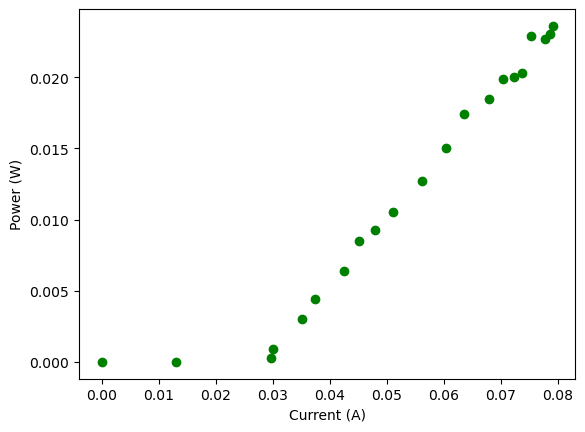

In [17]:
Current = [0.02E-3, 78.63E-3, 51.09E-3, 42.51E-3, 29.72E-3, 56.23E-3, 13.04E-3, 30E-3, 35.09E-3, 37.5E-3, 45.12E-3, 47.87E-3, 63.47E-3, 67.98E-3,
           70.32E-3, 60.46E-3, 75.31E-3, 72.26E-3, 73.76E-3, 77.75E-3, 79.07E-3]

Power = [0, 23E-3, 10.5E-3, 6.4E-3, 0.3E-3, 12.7E-3, 0, 0.9E-3, 3E-3, 4.4E-3, 8.5E-3, 9.3E-3, 17.4E-3, 18.5E-3, 19.9E-3, 15E-3, 22.9E-3 , 20E-3,
         20.3E-3, 22.7E-3, 23.6E-3]

plt.scatter(Current, Power, label='Power vs Current', color='green')
plt.xlabel('Current (A)')
plt.ylabel('Power (W)')
plt.show()